# 01 - Data ingestion and cleaning

**Project:** Motor insurance pricing model on the French MTPL dataset (freMTPL2)

## What this project is about, in simple terms

An insurer must decide, *before* a year starts, how much to charge each customer.
The fair price of the risk (before expenses, profit and taxes) is the **pure premium**:
the amount of money the insurer expects to pay out for that customer in one year.

Actuaries split the pure premium into two pieces that behave very differently:

$$\underbrace{\mathbb{E}[\text{cost per year}]}_{\text{pure premium}}
  = \underbrace{\mathbb{E}[\text{number of claims per year}]}_{\text{frequency}}
  \times \underbrace{\mathbb{E}[\text{cost of one claim}]}_{\text{severity}}$$

(this product form holds when the number of claims and the cost of each claim are
independent given the customer's characteristics - the standard *collective risk model*).

* **Frequency** - how *often* a customer has an accident. It is driven by behaviour and
  exposure to traffic: young drivers, a bad claims history, dense cities...
* **Severity** - how *expensive* an accident is once it happens. It is driven by different
  things: bodily injury vs. a scratched bumper, legal costs, the vehicle...

We model each separately, with a classical actuarial model (GLM) and a machine-learning model
(gradient boosting), and compare them.

## Goal of this notebook

Turn the raw public data into one **clean, trustworthy, policy-level table** that all the
following notebooks use. Concretely:

1. Download the two raw tables from the internet (OpenML) and keep an untouched copy.
2. Understand every column (data dictionary in plain words).
3. Check data quality: types, missing values, duplicates, impossible values.
4. Check that the two tables agree with each other, and fix what does not.
5. Treat extreme values (exposure > 1 year, very many claims, very large claims).
6. Build the modelling targets (frequency, average claim cost, pure premium) and save the result.

All the logic lives in the tested package `src/motor_pricing/` - the notebook calls it and
documents *why* each step is done.

## 0. Setup

We import the libraries and our own package. `motor_pricing` was installed in editable mode
(`pip install -e .`), so any change in `src/` is picked up immediately.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import motor_pricing
from motor_pricing import data as mpd
from motor_pricing.plotting import set_style, save, SERIES, INK_2

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 30)
print("project root:", motor_pricing.PROJECT_ROOT)

project root: C:\Users\mattr\Desktop\motor-insurance-pricing-model


## 1. Data ingestion - where the data comes from and how we fetch it

### The source
**freMTPL2** is a real motor third-party liability (MTPL) portfolio of a French insurer,
observed over roughly one year. *Third-party liability* is the compulsory cover that pays for
the damage the insured driver causes **to other people** (their car, their injuries) - not the
damage to the insured's own car.

It was published by the actuarial community in the R package **CASdatasets**
(C. Dutang & A. Charpentier) and is the standard benchmark used in actuarial research
(e.g. Noll, Salzmann & Wüthrich, *Case Study: French Motor Third-Party Liability Claims*, 2018).

It comes as **two tables**:

| Table | Content | Granularity |
|---|---|---|
| `freMTPL2freq` | policy characteristics + number of claims | one row per **policy** |
| `freMTPL2sev` | the cost of each claim | one row per **claim** |

### How we fetch it
Both tables are mirrored on **OpenML** (openml.org), a public repository of datasets with a
REST API. We use `sklearn.datasets.fetch_openml`, which:

1. calls the OpenML API over HTTPS asking for dataset id **41214** (`freMTPL2freq`) and
   **41215** (`freMTPL2sev`),
2. downloads the data file and its metadata (column names and types),
3. caches the download in `data/openml_cache/` and returns a pandas DataFrame.

Our function `load_raw()` wraps this: on the first run it downloads both tables, runs a
**schema validation** (all expected columns present, unique policy id, positive exposure and
amounts - so that a silent change upstream breaks loudly instead of corrupting results) and
stores an **untouched copy** as parquet files in `data/raw/`. Every later run reads those local
files, so the internet is only needed once.

Data folders are git-ignored: the repository holds the *code that rebuilds the data*, not the data.

In [2]:
freq_raw, sev_raw = mpd.load_raw()
print("freMTPL2freq:", freq_raw.shape, " -> one row per policy")
print("freMTPL2sev :", sev_raw.shape, " -> one row per claim")
print("raw files   :", sorted(p.name for p in mpd.RAW_DIR.iterdir()))

freMTPL2freq: (678013, 12)  -> one row per policy
freMTPL2sev : (26639, 2)  -> one row per claim
raw files   : ['freMTPL2freq.parquet', 'freMTPL2sev.parquet']


## 2. First look at the raw tables

In [3]:
freq_raw.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0000,1,0.1000,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0000,1,0.7700,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0000,1,0.7500,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0000,1,0.0900,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0000,1,0.8400,B,7,0,46,50,B12,'Diesel',76,R72


In [4]:
sev_raw.head()

,IDpol,ClaimAmount
0,1552,995.2000
1,1010996,"1,128.1200"
2,4024277,"1,851.1100"
3,4007252,"1,204.0000"
4,4046424,"1,204.0000"


## 3. Data dictionary - what each column means, in plain words

### Policy table `freMTPL2freq`

| Column | Plain meaning | Type / range | Why it may matter for risk |
|---|---|---|---|
| `IDpol` | Policy number - the unique id of the insurance contract. Used to link the two tables. | integer id | none (pure identifier) |
| `ClaimNb` | How many claims (accidents reported to the insurer) the policy had during the observation period. | 0, 1, 2, ... | it is the **frequency target** |
| `Exposure` | For how long the policy was observed, in **years**. 1.0 = a full year, 0.5 = six months, 0.08 = about one month. A policy can be short because it started or ended (or was renewed) during the year. | 0 - 2 (years) | a policy covered 1 year has twice as much chance to have a claim as one covered 6 months |
| `Area` | Density class of the town where the driver lives, from **A** (rural) to **F** (dense urban centre). | A ... F | more traffic -> more small accidents |
| `VehPower` | Power of the car, as an ordered class (French fiscal horsepower). | 4 ... 15 | powerful cars may be driven faster |
| `VehAge` | Age of the car in years. | 0 ... 100 | new cars are driven more; old cars less |
| `DrivAge` | Age of the driver in years (in France the licence is obtained from 18). | 18 ... 100 | young, inexperienced drivers have many more accidents |
| `BonusMalus` | The French **bonus-malus** coefficient (×100). Every driver starts at 100; each claim-free year multiplies it by 0.95 (a *bonus*, down to a floor of 50); each at-fault claim multiplies it by 1.25 (a *malus*). Below 100 = good history, above 100 = bad history. | 50 ... 230 | the single best summary of the driver's past behaviour |
| `VehBrand` | Car brand, anonymised into codes B1 ... B14. | 11 codes | brands correlate with car type and driver profile |
| `VehGas` | Fuel type: `Diesel` or `Regular` (petrol). | 2 values | diesel cars are typically driven many more km per year |
| `Density` | Number of inhabitants per km² in the driver's town. The continuous version of `Area`. | 1 ... 27,000 | same idea as `Area`, finer |
| `Region` | French administrative region (pre-2016 regions, INSEE codes, e.g. R11 = Île-de-France, R82 = Rhône-Alpes). | 22 codes | local road conditions, traffic, legal environment |

### Claim table `freMTPL2sev`

| Column | Plain meaning |
|---|---|
| `IDpol` | Policy number, links the claim to its policy. A policy with 2 claims appears twice. |
| `ClaimAmount` | What the insurer paid (or reserved) for this claim, in euros. It is the **severity** raw material. |

**Important:** there is *no* information on the driver's gender, profession, kilometres driven,
or the claim type. The models can only use the factors above.

## 4. Data quality checks

**Goal of this step:** before trusting any number, verify the basics - correct data types,
no missing values, no duplicated policies, and values inside plausible ranges.

### 4.1 Types and missing values

In [5]:
pd.DataFrame({
    "dtype": freq_raw.dtypes.astype(str),
    "missing": freq_raw.isna().sum(),
    "n_unique": freq_raw.nunique(),
})

,dtype,missing,n_unique
IDpol,float64,0,678013
ClaimNb,int64,0,11
Exposure,float64,0,181
Area,str,0,6
VehPower,int64,0,12
VehAge,int64,0,78
DrivAge,int64,0,83
BonusMalus,int64,0,115
VehBrand,str,0,11
VehGas,str,0,2


In [6]:
print("missing values in sev:", sev_raw.isna().sum().to_dict())
print("duplicated IDpol in freq:", freq_raw["IDpol"].duplicated().sum())
print("IDpol is integer-valued:", bool((freq_raw["IDpol"] % 1 == 0).all()))
print("VehGas raw values:", freq_raw["VehGas"].unique())

missing values in sev: {'IDpol': 0, 'ClaimAmount': 0}
duplicated IDpol in freq: 0
IDpol is integer-valued: True
VehGas raw values: <ArrowStringArray>
[''Regular'', ''Diesel'']
Length: 2, dtype: str


**What we see**

* **No missing values** anywhere and **no duplicated policy ids** - good.
* `IDpol` is stored as a *float* in the OpenML version although it is an identifier; we will
  cast it to integer (floats can lose precision and make joins fragile).
* `VehGas` values carry **literal quote characters** (`'Diesel'`): an artefact of the ARFF file
  format used by OpenML. We strip them.
* The categorical columns (`Area`, `VehBrand`, `VehGas`, `Region`) will be stored as pandas
  *categories*, which is both memory-efficient and what LightGBM expects for native categorical
  handling.

### 4.2 Ranges of the numeric columns

In [7]:
freq_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
IDpol,"678,013.0000","2,621,856.9211","1,641,782.7527",1.0000,"1,157,951.0000","2,272,152.0000","4,046,274.0000","6,114,330.0000"
ClaimNb,"678,013.0000",0.0532,0.2401,0.0000,0.0000,0.0000,0.0000,16.0000
Exposure,"678,013.0000",0.5288,0.3644,0.0027,0.1800,0.4900,0.9900,2.0100
VehPower,"678,013.0000",6.4546,2.0509,4.0000,5.0000,6.0000,7.0000,15.0000
VehAge,"678,013.0000",7.0443,5.6662,0.0000,2.0000,6.0000,11.0000,100.0000
DrivAge,"678,013.0000",45.4991,14.1374,18.0000,34.0000,44.0000,55.0000,100.0000
BonusMalus,"678,013.0000",59.7615,15.6367,50.0000,50.0000,50.0000,64.0000,230.0000
Density,"678,013.0000","1,792.4224","3,958.6466",1.0000,92.0000,393.0000,"1,658.0000","27,000.0000"


In [8]:
sev_raw["ClaimAmount"].describe(percentiles=[0.5, 0.9, 0.99, 0.999])

count      26,639.0000
mean        2,278.5364
std        29,297.4813
min             1.0000
50%         1,172.0000
90%         2,799.0720
99%        16,793.7044
99.9%     162,784.4424
max     4,075,400.5600
Name: ClaimAmount, dtype: float64

**What we see**

* `Exposure` goes up to **2.01 years**. The data is supposed to cover one accounting year, so
  values above 1 are recording errors (Noll et al. 2018 make the same observation). -> step 6.
* `ClaimNb` goes up to **16** claims in a year for a single policy, which is not plausible for a
  private car - more likely data errors or fleet-like contracts. -> step 6.
* `VehAge` and `DrivAge` reach 100: rare but kept (trees are insensitive to them, and the GLM
  will group them into an open "71+" / "11+" class).
* `ClaimAmount` is extremely **skewed**: median ≈ €1,170 but maximum ≈ €4 million. The mean
  (≈ €2,280) is twice the median - the hallmark of a heavy right tail. -> step 7.

## 5. Do the two tables agree with each other?

**Goal of this step:** the frequency table says how many claims each policy had (`ClaimNb`);
the severity table lists the claims with their cost. These two views of the same events must
match - otherwise the frequency model would learn claims that never get a cost, and
frequency × severity would not add up to the real total cost.

We aggregate the claim table per policy and compare the *declared* number of claims with the
number of claims that actually have an amount.

In [9]:
freq_t = mpd.clean_freq_types(freq_raw)
sev_agg = mpd.aggregate_severity(sev_raw)
check = freq_t[["IDpol", "ClaimNb", "Exposure"]].join(sev_agg, on="IDpol")
check["ClaimNbSev"] = check["ClaimNbSev"].fillna(0).astype(int)

print("claims declared in freq table :", check["ClaimNb"].sum())
print("claims with an amount (sev)   :", len(sev_raw))
print("sev policy ids missing in freq:", (~sev_agg.index.isin(freq_t["IDpol"])).sum())
pd.crosstab(check["ClaimNb"].clip(upper=5), check["ClaimNbSev"].clip(upper=5),
            rownames=["ClaimNb (freq table, 5 = 5+)"], colnames=["claims with amount (sev, 5 = 5+)"])

claims declared in freq table : 36102
claims with an amount (sev)   : 26639
sev policy ids missing in freq: 6


"claims with amount (sev, 5 = 5+)",0,1,2,3,4,5
"ClaimNb (freq table, 5 = 5+)",,,,,,
0,643953,0,0,0,0,0
1,8608,23570,0,0,0,0
2,485,1,1298,0,0,0
3,20,0,0,62,0,0
4,2,0,0,0,5,0
5,1,0,0,0,0,8


Off the diagonal of this table are the inconsistent policies. Almost all of them are in the first
column: policies that **declare claims but have no cost recorded at all**. Where are they?

In [10]:
bad = check[(check["ClaimNb"] > 0) & (check["ClaimNbSev"] == 0)]
claimants = check[check["ClaimNb"] > 0]
bins = [0, 25_000, 100_000, 1_000_000, 3_000_000, 7_000_000]
loc = pd.DataFrame({
    "policies with ClaimNb>0": pd.cut(claimants["IDpol"], bins).value_counts().sort_index(),
    "...of which without any amount": pd.cut(bad["IDpol"], bins).value_counts().sort_index(),
})
loc["share without amount"] = loc.iloc[:, 1] / loc.iloc[:, 0]
print(f"policies with claims but no amount: {len(bad):,}")
loc

policies with claims but no amount: 9,116


,policies with ClaimNb>0,...of which without any amount,share without amount
IDpol,,,
"(0, 25000]",9388,9094,0.9687
"(25000, 100000]",2278,2,0.0009
"(100000, 1000000]",1822,3,0.0016
"(1000000, 3000000]",10689,11,0.0010
"(3000000, 7000000]",9883,6,0.0006


**Interpretation**

* Out of the policies that declare at least one claim, about 9,100 have **no claim cost at all**.
* They are **not random**: virtually all of them have a policy number below 25,000, where
  ~97% of the policies declaring a claim have no amount at all, against ~0.1% elsewhere. This is a
  *systematic* recording problem of one block of the portfolio (a known issue of this dataset),
  not real claims that happened to cost zero.

**Decision.** We redefine `ClaimNb` as **the number of claims that have a recorded amount**.

* *Mathematically*, frequency and severity are then estimated on the *same* set of events, so
  that $\hat{\text{freq}}\times\hat{\text{sev}}$ is an unbiased estimate of the observed cost per year.
* *In real-world terms*: overall the policy table declares 36,102 claims but only 26,639 have a
  cost (+36%). Keeping the declared counts would teach the frequency model that the drivers of
  one faulty block have many accidents that never cost anything, and would inflate their premium.
  We prefer to possibly under-count a few genuine claims in that block. The original column is kept as `ClaimNbOriginal`
  for transparency.
* The 6 claims whose policy number does not exist in the policy table cannot be attached to any
  risk profile and are dropped.

## 6. Extreme values of exposure and claim counts

**Goal of this step:** neutralise a few impossible values without losing the policies.

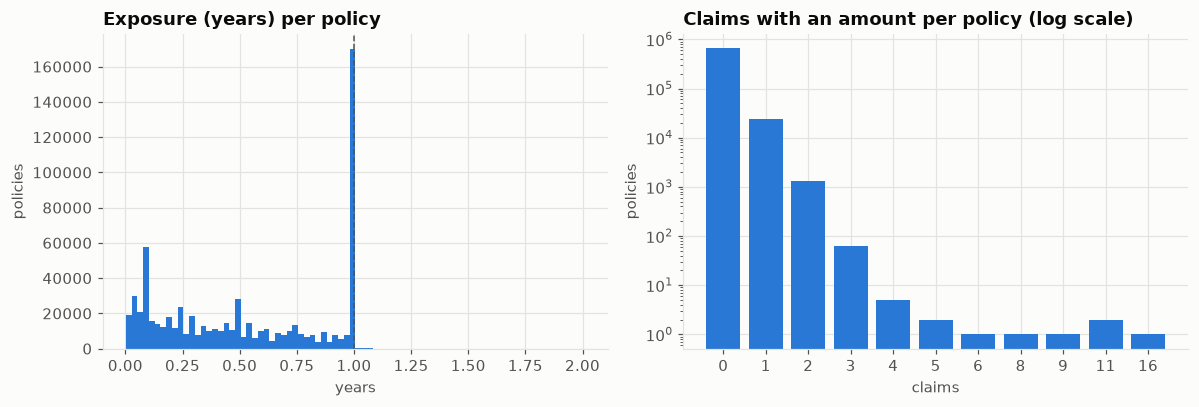

policies with exposure > 1 year: 1224
policies with > 4 claims: 8


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(freq_raw["Exposure"], bins=80, color=SERIES[0])
axes[0].axvline(1, color=INK_2, ls="--", lw=1)
axes[0].set(title="Exposure (years) per policy", xlabel="years", ylabel="policies")
cnt = check["ClaimNbSev"].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values, color=SERIES[0])
axes[1].set_yscale("log")
axes[1].set(title="Claims with an amount per policy (log scale)", xlabel="claims", ylabel="policies")
plt.tight_layout(); save(fig, "01_exposure_claimnb"); plt.show()
print("policies with exposure > 1 year:", (freq_raw["Exposure"] > 1).sum())
print("policies with > 4 claims:", (check["ClaimNbSev"] > 4).sum())

**What we see and what we decide**

* **Exposure** is spread over the whole year with spikes at round values (1 year, 6 months...)
  and a large mass at 1.0 (policies in force all year). 1,224 policies (0.18%) exceed one year:
  we **cap exposure at 1**. Capping (instead of deleting) keeps their claims in the data.
* **Claim counts**: after the recount of step 5, 96% of policies have 0 claims, and only a handful
  have more than 4. We **cap `ClaimNb` at 4** (as in Noll et al. 2018).
  The money of those claims is *kept* in the total amount, so no cost is lost.

*Why exposure matters so much:* a policy observed for one month with no claim is much weaker
evidence of being a good risk than a policy observed for a full year with no claim. Every model
will use exposure as the **"amount of observation"** behind each row (an offset in the GLM, a
weight elsewhere).

## 7. Large claims

**Goal of this step:** decide how to handle the very few, very expensive claims that dominate
total cost, so that they do not distort the severity model.

### Why this matters - a bit of theory
The severity model estimates the *expected* cost of a claim as a function of the rating
factors. Means are not robust: a single €4M bodily-injury claim moves the average of the group it
falls in by thousands of euros, and the model would "learn" that, say, drivers of brand B12 in
region R82 are expensive - while it was just one unlucky, essentially random event.

Standard actuarial practice (*large-loss capping*) is therefore:

1. cap every **single** claim at a threshold $c$: the model learns from $\min(X, c)$, the
   *attritional* (everyday) part of the cost, which is predictable from the risk factors;
2. spread the **excess** $\sum (X - c)^+$ over all policies as a proportional loading, because
   large losses are rare, mostly random and not reliably attributable to a specific profile.

The total amount of money is preserved; only its *allocation* between customers changes.

In [12]:
amt = sev_raw["ClaimAmount"]
total = amt.sum()
rows = []
for c in [10_000, 20_000, 50_000, 100_000, 200_000, 500_000]:
    rows.append({
        "cap (EUR)": f"{c:,}",
        "claims above cap": int((amt > c).sum()),
        "% of claims": (amt > c).mean() * 100,
        "% of total cost above cap": (amt - c).clip(lower=0).sum() / total * 100,
    })
pd.DataFrame(rows)

,cap (EUR),claims above cap,% of claims,% of total cost above cap
0,"10,000",485,1.8206,34.5387
1,"20,000",218,0.8183,29.2803
2,"50,000",89,0.3341,22.5606
3,"100,000",42,0.1577,17.6835
4,"200,000",21,0.0788,12.7439
5,"500,000",4,0.0150,9.1503


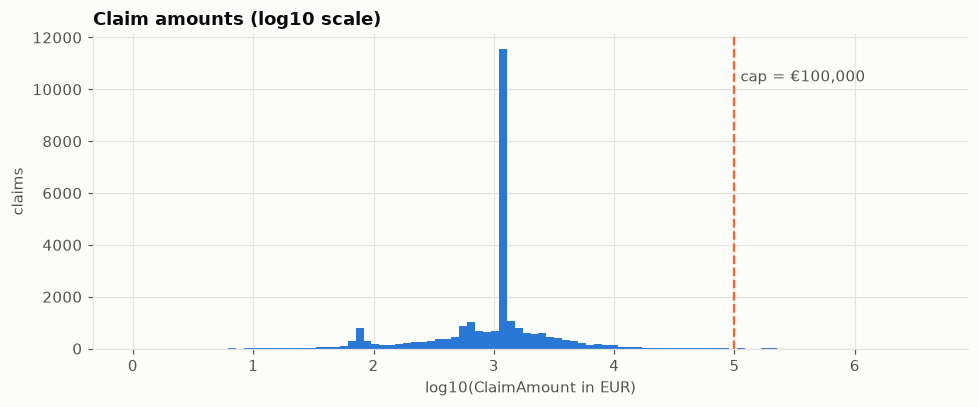

most frequent amounts:
ClaimAmount
1,204.0000    4792
1,128.1200    3056
1,172.0000    2072
1,128.0000     831
602.0000       433
Name: count, dtype: int64


In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(np.log10(amt), bins=100, color=SERIES[0])
ax.axvline(5, color=SERIES[1], lw=1.5, ls="--")
ax.text(5.05, ax.get_ylim()[1] * 0.85, "cap = €100,000", color=INK_2)
ax.set(title="Claim amounts (log10 scale)", xlabel="log10(ClaimAmount in EUR)", ylabel="claims")
plt.tight_layout(); save(fig, "01_claim_amounts"); plt.show()
print("most frequent amounts:"); print(amt.value_counts().head(5))

**What we see**

* On a log scale amounts look roughly bell-shaped around €1,000-€1,500 (i.e. roughly
  *log-normal / Gamma-like*), with a long right tail.
* There are **huge spikes at identical values** (€1,204 appears ~4,800 times, €1,128.12 ~3,000
  times). These are flat-rate settlements: French insurers settle most small material-damage
  claims between themselves at a fixed conventional amount (the IRSA convention). It is a
  feature of the market, not an error, and it means a large share of claims carries almost no
  information about the policyholder's profile.
* With a cap at **€100,000** only **42 claims (0.16%)** are affected, but they carry
  **~18% of the total cost**.

**Decision: cap single claims at €100,000.** This is a judgement call, typical of practice:
a lower cap (e.g. €20k) would also cut "normal" bodily-injury claims that the factors can partly
explain; a higher one would leave the severity model at the mercy of a few dozen claims.
We keep both `ClaimAmount` (raw, used to evaluate the final premium on real money) and
`ClaimAmountCapped` (used to *train* severity models).

## 8. Build the clean modelling table

**Goal of this step:** apply all the decisions above in one reproducible function call and
record exactly what changed.

`build_modelling_table` performs: type fixing -> severity aggregation per policy (raw and capped)
-> left join on `IDpol` -> recount of `ClaimNb` -> exposure cap at 1 -> claim-count cap at 4.
`add_targets` then creates:

| Target | Formula | Meaning |
|---|---|---|
| `Frequency` | `ClaimNb / Exposure` | claims per policy-year (the frequency target) |
| `AvgClaim` | `ClaimAmountCapped / ClaimNb` (only if ClaimNb > 0) | average capped cost of one claim (the severity target) |
| `PurePremium` | `ClaimAmount / Exposure` | observed cost per policy-year (used for final evaluation) |

In [14]:
LARGE_CLAIM_CAP = 100_000
df, report = mpd.build_modelling_table(freq_raw, sev_raw, large_claim_cap=LARGE_CLAIM_CAP)
df = mpd.add_targets(df)
report.as_series().to_frame()

,value
n_policies_raw,678013
n_claims_raw,26639
claims_raw_freq_table,36102
sev_ids_not_in_freq,6
policies_claimnb_changed,9117
exposure_capped,1224
claimnb_capped,8


In [15]:
df.head()

,IDpol,ClaimNb,ClaimNbOriginal,ClaimAmount,ClaimAmountCapped,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,Frequency,AvgClaim,PurePremium
0,1,0,1,0.0000,0.0000,0.1000,D,5,0,55,50,B12,Regular,1217,R82,0.0000,NaN,0.0000
1,3,0,1,0.0000,0.0000,0.7700,D,5,0,55,50,B12,Regular,1217,R82,0.0000,NaN,0.0000
2,5,0,1,0.0000,0.0000,0.7500,B,6,2,52,50,B12,Diesel,54,R22,0.0000,NaN,0.0000
3,10,0,1,0.0000,0.0000,0.0900,B,7,0,46,50,B12,Diesel,76,R72,0.0000,NaN,0.0000
4,11,0,1,0.0000,0.0000,0.8400,B,7,0,46,50,B12,Diesel,76,R72,0.0000,NaN,0.0000


## 9. Sanity checks on the clean table

**Goal:** verify that nothing was lost or created by mistake, and compute the portfolio-level
figures that every model must be able to reproduce.

In [16]:
known_ids = sev_raw["IDpol"].isin(df["IDpol"])
assert np.isclose(df["ClaimAmount"].sum(), sev_raw.loc[known_ids, "ClaimAmount"].sum())
assert df["IDpol"].is_unique and len(df) == len(freq_raw)
assert (df.loc[df["ClaimNb"] == 0, "ClaimAmount"] == 0).all()
assert (df.loc[df["ClaimNb"] > 0, "AvgClaim"] > 0).all()

portfolio = pd.Series({
    "policies": len(df),
    "total exposure (policy-years)": df["Exposure"].sum(),
    "claims": df["ClaimNb"].sum(),
    "policies with >= 1 claim (%)": (df["ClaimNb"] > 0).mean() * 100,
    "claim frequency (claims / policy-year)": df["ClaimNb"].sum() / df["Exposure"].sum(),
    "average claim cost, raw (EUR)": df["ClaimAmount"].sum() / df["ClaimNb"].sum(),
    "average claim cost, capped (EUR)": df["ClaimAmountCapped"].sum() / df["ClaimNb"].sum(),
    "pure premium, raw (EUR / policy-year)": df["ClaimAmount"].sum() / df["Exposure"].sum(),
    "large-loss loading factor": df["ClaimAmount"].sum() / df["ClaimAmountCapped"].sum(),
})
portfolio.to_frame("value")

,value
policies,"678,013.0000"
total exposure (policy-years),"358,360.1055"
claims,"26,405.0000"
policies with >= 1 claim (%),3.6790
claim frequency (claims / policy-year),0.0737
"average claim cost, raw (EUR)","2,268.8588"
"average claim cost, capped (EUR)","1,867.1538"
"pure premium, raw (EUR / policy-year)",167.1760
large-loss loading factor,1.2151


**Interpretation of the portfolio figures**

* After cleaning we have **26,405 claims** (26,639 minus the 6 orphan claims, minus the counts
  removed by the cap at 4 claims per policy) over **358,360 policy-years** of exposure.
* **Claim frequency ≈ 0.074 claims per policy-year**: on average a driver files a claim
  about once every 13-14 years. Claims are *rare events* - this is why a Poisson model (designed
  for counts of rare events) is natural, and why most of the signal is in a small fraction of rows.
* **Average claim cost ≈ €2,270** (raw) vs ≈ €1,870 once single claims are capped at €100k.
* **Pure premium ≈ €167 per policy-year**: the average amount the insurer needs per year
  *just to pay claims* (the commercial premium adds expenses, commissions, profit margin and taxes).
* **Large-loss loading ≈ 1.2**: the capped models will be multiplied by this factor so that the
  final premium covers the real (uncapped) cost.

These numbers are the *benchmark* every model must reproduce at portfolio level ("balance").

## 10. Save the processed table

The clean table is written to `data/processed/fremtpl2_clean.parquet`. All later notebooks start
from it with `motor_pricing.data.load_processed()`.

In [17]:
mpd.save_processed(df)
reloaded = mpd.load_processed()
print(reloaded.shape)
reloaded.dtypes.to_frame("dtype").T

(678013, 18)


,IDpol,ClaimNb,ClaimNbOriginal,ClaimAmount,ClaimAmountCapped,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,Frequency,AvgClaim,PurePremium
dtype,int64,int64,int64,float64,float64,float64,category,int64,int64,int64,int64,category,category,int64,category,float64,float64,float64


## Summary

| Step | What we did | Why |
|---|---|---|
| Ingestion | Downloaded freMTPL2freq / freMTPL2sev from OpenML (ids 41214 / 41215), validated the schema, stored an untouched parquet copy | reproducibility, offline re-runs, early failure on upstream changes |
| Types | Cast `IDpol` to int, stripped quotes in `VehGas`, categoricals as `category` | correct joins and native categorical handling |
| Consistency | Recomputed `ClaimNb` from the claim table; dropped 6 orphan claims | frequency and severity must describe the same events |
| Exposure | Capped at 1 year | values > 1 are recording errors |
| Claim counts | Capped at 4 | implausible counts for a private car |
| Large claims | Single claims capped at €100k for severity training; excess kept for the final loading | robust severity estimates without losing money |
| Targets | `Frequency`, `AvgClaim`, `PurePremium` | the quantities the models will predict |

Next: **02 - Exploratory data analysis**, where we look at how frequency and severity vary
with each rating factor.